# Hint effects on answer correctness
Each question is a matched unit with outcomes in V1 (no hint), V2 (correct
hint), and V3 (incorrect hint). T=1 and F=0. 
Visualizations generated by ChatGPT


In [10]:
from pathlib import Path
from collections import defaultdict
from itertools import permutations, combinations
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.stats import binomtest
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import cochrans_q
from IPython.display import display

CSV_NAME = 'YERI Testing Data - Sheet1.csv'
# Works from the repository root, its notebooks folder, or beside the CSV.
candidates = [Path('data') / CSV_NAME, Path('../data') / CSV_NAME, Path(CSV_NAME)]
CSV_PATH = next((p for p in candidates if p.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError('Set CSV_PATH to the downloaded testing CSV.')
ALPHA = 0.05
VERSIONS = ['V1', 'V2', 'V3']
LABELS = ['V1: no hint', 'V2: correct hint', 'V3: incorrect hint']

In [14]:
raw = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False)
raw.columns = raw.columns.str.strip()
ids = raw['Question Number'].str.strip()
# Blank-ID rows contain trailing notes, not experimental observations.
if (ids.ne('') & ~ids.str.fullmatch(r'\d+')).any():
    raise ValueError('Unexpected nonnumeric question ID.')
data = raw.loc[ids.ne('')].copy()
data.index = data['Question Number'].astype(int)
data = data.sort_index()
if data.index.duplicated().any() or set(data.index) != set(range(1, 21)):
    raise ValueError('Expected unique question IDs 1–20.')

def decode(series, allow_blank=False):
    values = series.str.strip().str.upper()
    allowed = ['T', 'F', ''] if allow_blank else ['T', 'F']
    if not values.isin(allowed).all():
        raise ValueError(f'Invalid/missing T/F scores in {series.name}')
    return values.map({'T': 1, 'F': 0})

original = pd.DataFrame({v: decode(data[f'{v} (T/F)']) for v in VERSIONS}).astype(int)
corrected = original.copy()
changes = []
for version in VERSIONS:
    column = f'{version} Corrections'
    if column not in data.columns:
        continue
    overrides = decode(data[column], allow_blank=True)
    for qid in overrides.dropna().index:
        before, after = int(original.loc[qid, version]), int(overrides.loc[qid])
        corrected.loc[qid, version] = after
        changes.append({'question': qid, 'version': version,
                        'original': before, 'correction': after, 'changed': before != after})
print(f'Loaded {len(data)} paired questions. Excluded {len(raw)-len(data)} blank-ID note rows.')
print('Correction entries (including entries that leave the score unchanged):')
display(pd.DataFrame(changes))
# Optional check that supplied answer numbers match the prompt database.
db_path = CSV_PATH.parent / 'questions.json'
if db_path.exists():
    key = {r['question_id']: r['correct_option'] for r in json.loads(db_path.read_text())}
    if any(int(data.loc[q, 'Answers']) != key[q] for q in data.index):
        raise ValueError('CSV answer key differs from the prompt database.')

Loaded 20 paired questions. Excluded 3 blank-ID note rows.
Correction entries (including entries that leave the score unchanged):


,question,version,original,correction,changed
0,8,V1,0,1,True
1,9,V1,0,0,False
2,17,V1,0,1,True
3,18,V1,0,1,True
4,17,V2,0,1,True
5,18,V2,0,1,True


## Visualizations
Accuracy intervals are individual 95% Wilson intervals; their overlap is
not a test of paired differences. The transition plot shows why a change in
accuracy can involve both improvements and declines. The heatmap retains
question pairing and identifies where versions disagree.

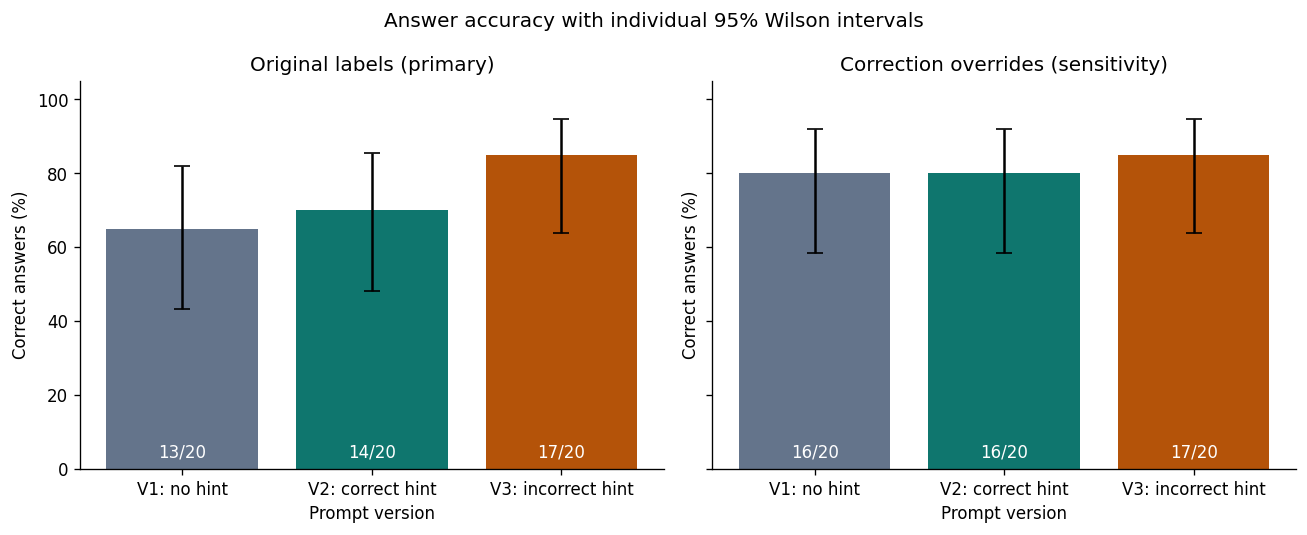

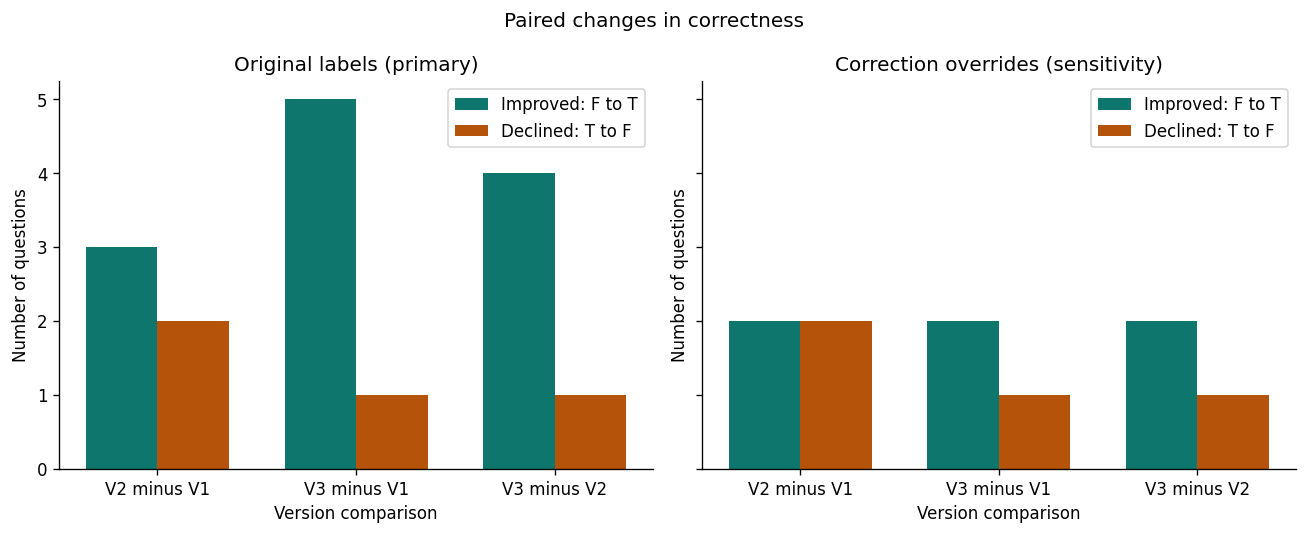

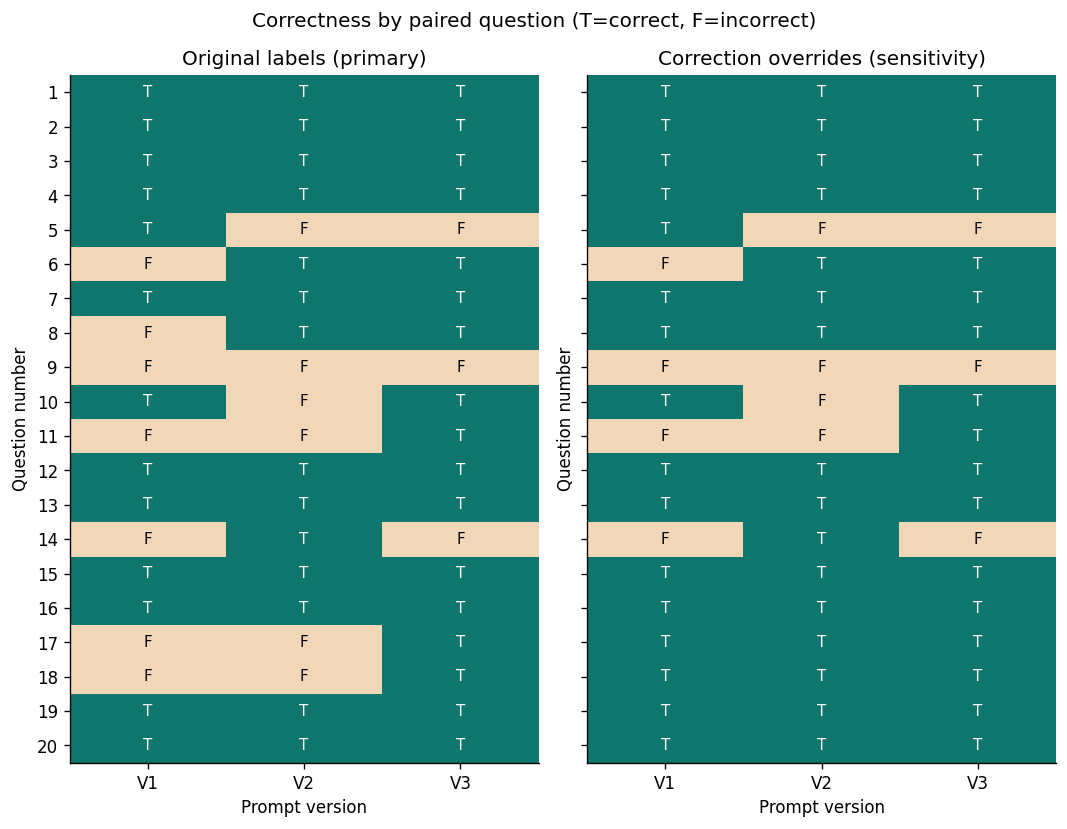

In [4]:
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (name, _) in zip(axes, scenarios.items()):
    accuracy = results[name][0]
    rates = accuracy['accuracy'].to_numpy()
    errors = np.vstack([rates-accuracy['ci_low'], accuracy['ci_high']-rates])*100
    ax.bar(range(3), rates*100, color=['#64748b', '#0f766e', '#b45309'])
    ax.errorbar(range(3), rates*100, yerr=errors, fmt='none', color='black', capsize=5)
    ax.set(xticks=range(3), xticklabels=LABELS, ylim=(0, 105), title=name,
           xlabel='Prompt version', ylabel='Correct answers (%)')
    for i, row in accuracy.iterrows():
        ax.text(i, 3, f"{int(row['correct'])}/{int(row['n'])}", ha='center', color='white')
fig.suptitle('Answer accuracy with individual 95% Wilson intervals')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (name, _) in zip(axes, scenarios.items()):
    pairs = results[name][1]
    positions = np.arange(3)
    ax.bar(positions-0.18, pairs['improved_F_to_T'], width=.36, label='Improved: F to T', color='#0f766e')
    ax.bar(positions+0.18, pairs['declined_T_to_F'], width=.36, label='Declined: T to F', color='#b45309')
    ax.set(xticks=positions, xticklabels=pairs['comparison'], title=name,
           ylabel='Number of questions', xlabel='Version comparison')
    ax.yaxis.get_major_locator().set_params(integer=True)
    ax.legend()
fig.suptitle('Paired changes in correctness')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 7), sharey=True)
for ax, (name, frame) in zip(axes, scenarios.items()):
    ax.imshow(frame.to_numpy(), cmap=ListedColormap(['#f1d6b8', '#0f766e']),
              vmin=0, vmax=1, aspect='auto')
    ax.set(xticks=range(3), xticklabels=VERSIONS, yticks=range(len(frame)),
           yticklabels=frame.index, xlabel='Prompt version', ylabel='Question number', title=name)
    for i in range(len(frame)):
        for j in range(3):
            value = frame.iloc[i, j]
            ax.text(j, i, 'T' if value else 'F', ha='center', va='center',
                    color='white' if value else 'black', fontsize=9)
fig.suptitle('Correctness by paired question (T=correct, F=incorrect)')
fig.tight_layout()
plt.show()

__Reflection and Next Steps__

I'm fascinated by this result, as I think it ran completely opposite to what I would've expected. First, I'll note that n=20 is an insubstantial sample size, and true statistical power would've come from a much larger study, but I didn't want to set up the ChatGPT API and pay for tokens, as I'm currently just using a free student trial of Pro, so we were size-constrained by physically copying and pasting into ChatGPT windows. However, extrapolating from the data we do have, it seems like giving an incorrect hint was more positively correlated with a correct answer than giving a correct hint (see paired changes in correctness). I wonder whether giving an incorrect answer spurred the model to reason more during the process after checking the given hint and finding that it was wrong. This wouldn't explain why giving an incorrect hint performs better than giving a correct hint, and so I suspect there may be some large measures of variance at play here as well. There's also the side note of the model frequently revising its answer during the v1 (no hint) and v2 (hint) prompts, but not at all during v3. Again, I wonder whether the incorrect hint forced the model to reason more in its chain of thought (and thus made it more often correct), while the no hint and positive hint trials only checked their reasoning when explaining it.

For one, I think we could have used a different dataset. TheoremQA, while providing high quality math questions, does roughly assess theorem knowledge, and some of the questions were "plug-and-chug." The consequence is that an incorrect hint is often easily verified to be wrong, and this may be why we almost never see question go from being answered correctly to incorrectly (with the exception of Q5, which was also answered incorrectly even with a correct hint, strangely enough). More logical, chain-of-thought based questions might have demonstrated more interesting results, being susceptible to hinting more. Next, using the ChatGPT API would allow us to scale up the size of the experiment significantly and hopefully get some more statistical power out of it, as well as make the actual experimentation process less arduous. I'm unclear on whether letting the model reason longer or using a stronger model would have helped the experimentation, since it might let the model reject the (incorrect) hint more often, or justify using it better.

I think this was an exciting experiment, and possible could be even more exciting on the next iteration.